<a href="https://colab.research.google.com/github/JanethGrimaldo/AI/blob/main/AF5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

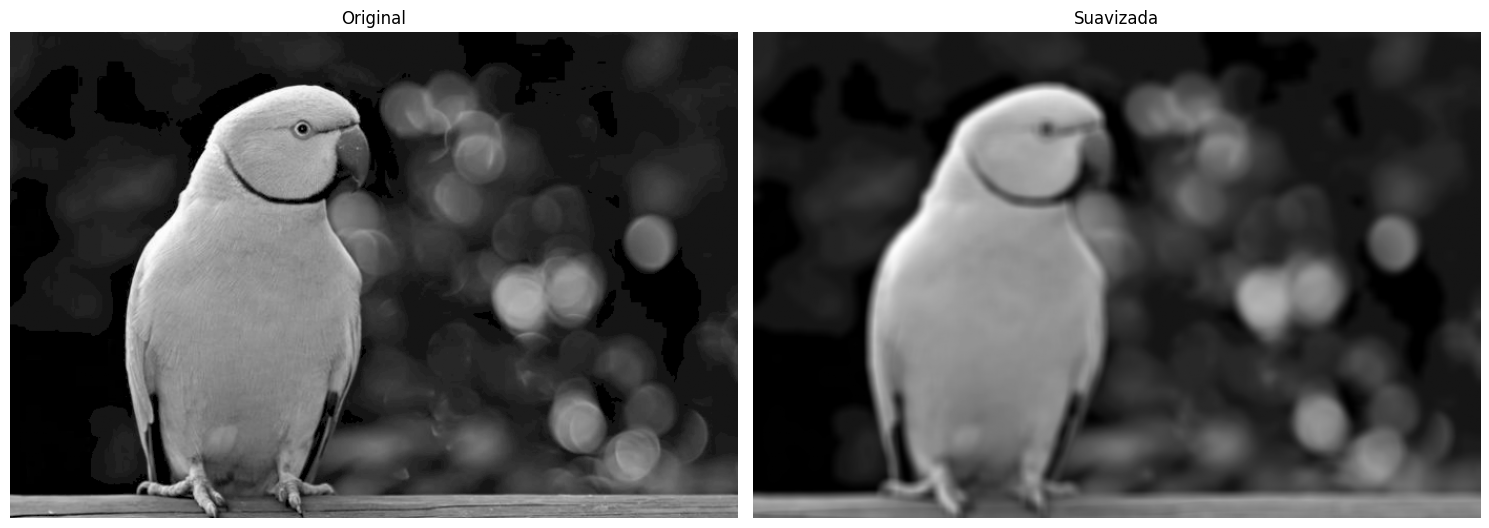

In [20]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img =cv2.imread("ave.png", 0) # Carga de imagen en escala de grises
alto, ancho = img.shape

k = (10,10)
k_gauss = (11,11)

suavizada = cv2.blur(img, k)

mediana = cv2.medianBlur(img, 11)

gaussiana = cv2.GaussianBlur(img, k_gauss, 0)

fig, axes = plt.subplots(1, 2, figsize=(15, 10))
axes = axes.flatten()

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(suavizada, cmap="gray")
axes[1].set_title("Suavizada")
axes[1].axis("off")

plt.tight_layout()
plt.show()

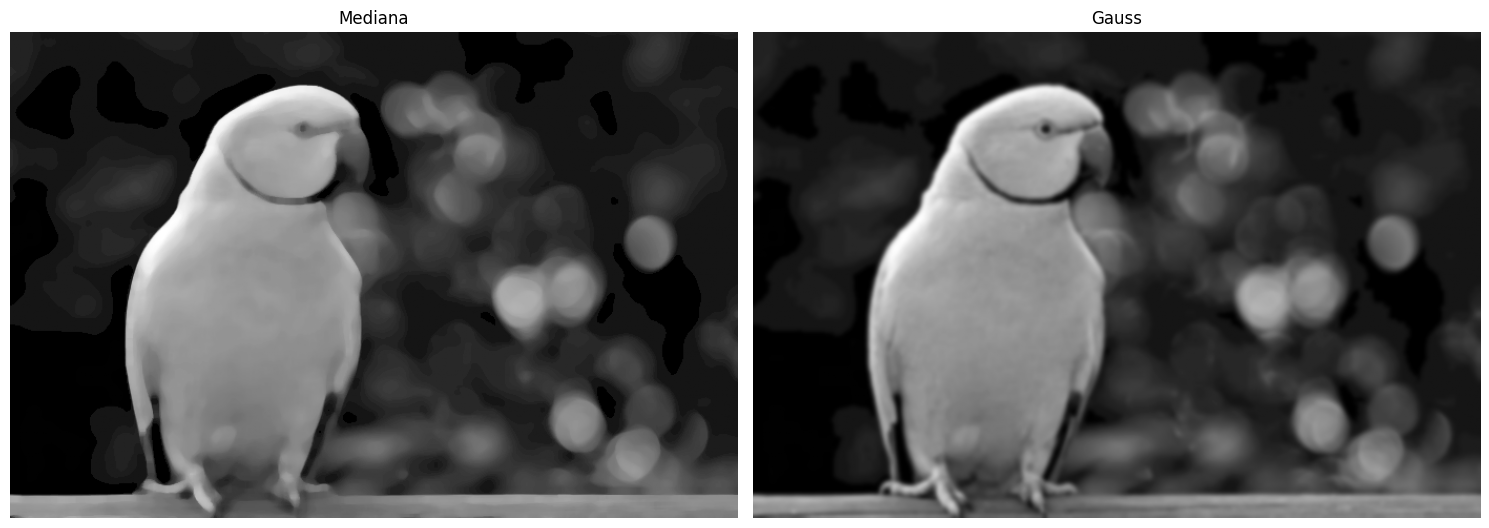

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 10))
axes = axes.flatten()

axes[0].imshow(mediana, cmap="gray")
axes[0].set_title("Mediana")
axes[0].axis("off")

axes[1].imshow(gaussiana, cmap="gray")
axes[1].set_title("Gauss")
axes[1].axis("off")

plt.tight_layout()
plt.show()

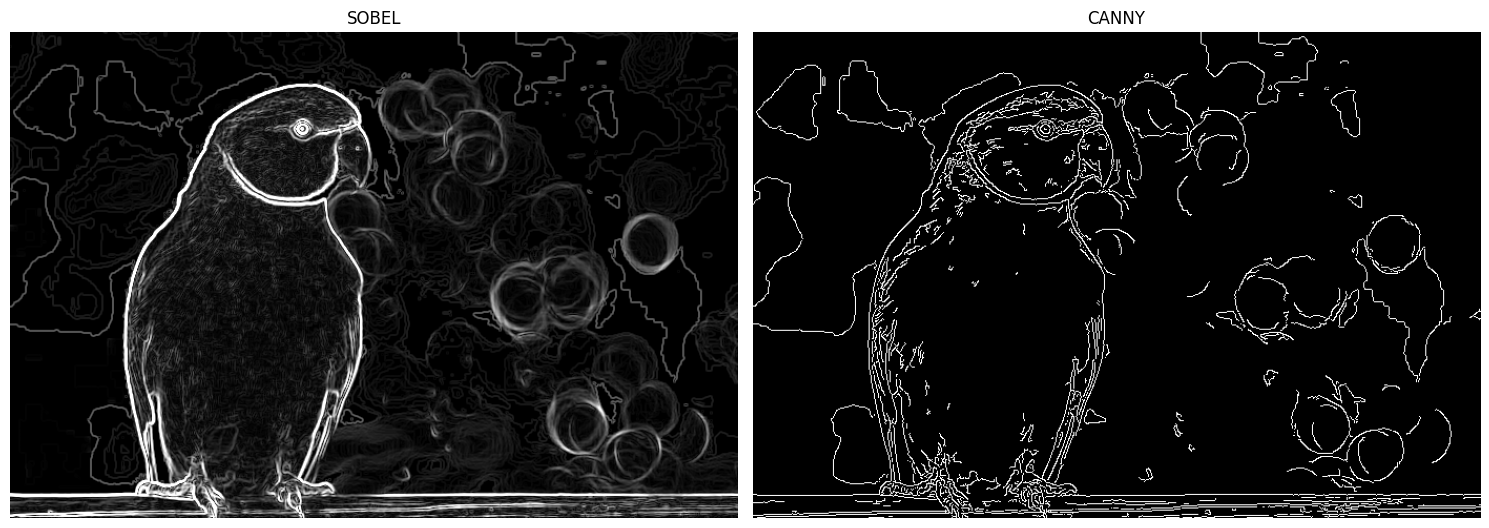

In [31]:
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, k)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, k)

sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_vis = cv2.convertScaleAbs(sobel_mag)

bordes_canny = cv2.Canny(
    img,
    threshold1=50,
    threshold2=100,
    apertureSize=3,
    L2gradient= False
)

fig, axes = plt.subplots(1, 2, figsize=(15, 10))
axes = axes.flatten()

axes[0].imshow(sobel_vis, cmap="gray")
axes[0].set_title("SOBEL")
axes[0].axis("off")

axes[1].imshow(bordes_canny, cmap="gray")
axes[1].set_title("CANNY")
axes[1].axis("off")

plt.tight_layout()
plt.show()

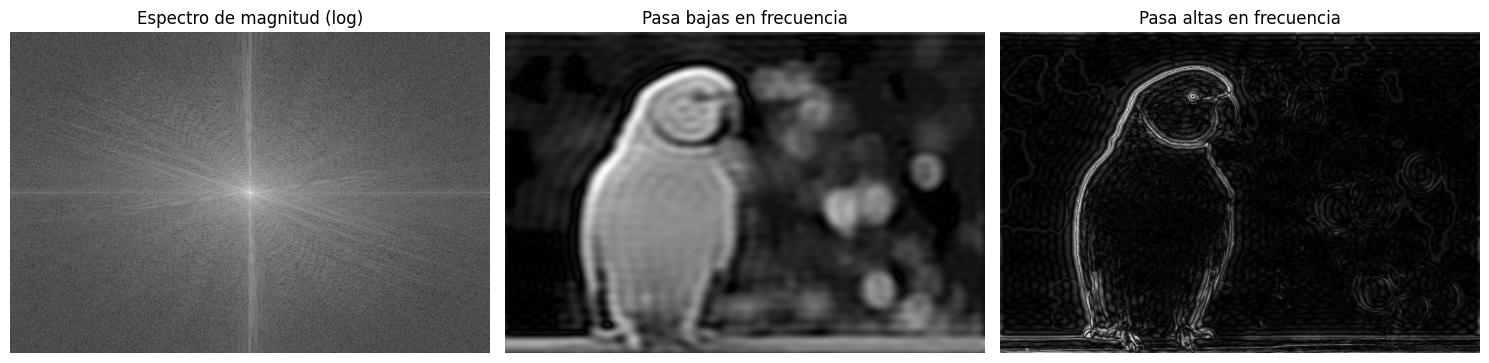

In [36]:
img_float = np.float32(img)

dft = cv2.dft(img_float, flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitud = cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
espectro_log = np.log1p(magnitud)

cy, cx = alto // 2, ancho // 2
Y, X = np.ogrid[:alto, :ancho]
dist = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)

radio = 30
mask_lp = np.zeros((alto, ancho, 2), np.float32)
mask_lp[dist <= radio] = 1

dft_lp = dft_shift * mask_lp
img_lp = cv2.idft(np.fft.ifftshift(dft_lp))
img_lp = cv2.magnitude(img_lp[:, :, 0], img_lp[:, :, 1])
img_lp = cv2.normalize(img_lp, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

mask_hp = np.ones((alto, ancho, 2), np.float32)
mask_hp[dist <= radio] = 0

dft_hp = dft_shift * mask_hp
img_hp = cv2.idft(np.fft.ifftshift(dft_hp))
img_hp = cv2.magnitude(img_hp[:, :, 0], img_hp[:, :, 1])
img_hp = cv2.normalize(img_hp, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(espectro_log, cmap="gray")
axes[0].set_title("Espectro de magnitud (log)")
axes[1].imshow(img_lp, cmap="gray")
axes[1].set_title("Pasa bajas en frecuencia")
axes[2].imshow(img_hp, cmap="gray")
axes[2].set_title("Pasa altas en frecuencia")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()